### CSE5026 Foundation and Frontiers of Cognitive Science
## Lab: Word Surprisal and Eye Fixation Time


In this lab, we will use **Qwen3-0.6B-Base** to estimate word surprisal and examine its relationship with eye fixation time.

We will work with 10 passages from the OneStop eye-tracking dataset. The lab is organized as follows:

- **T1 and T2:** load the data and compute token surprisal with Hugging Face Transformers.
- **T3 and T4:** map tokens to words, analyze all 10 passages, and visualize the relationship between surprisal and fixation time.

Surprisal is defined as $s(x_t)=-\log p(x_t\mid x_{<t})$. We use natural logarithms, so the values are measured in **nats**.


In [1]:
import json
import re
from pathlib import Path

import numpy as np
import pandas as pd
import torch
from scipy.stats import pearsonr
from transformers import AutoModelForCausalLM, AutoTokenizer

pd.set_option("display.max_colwidth", 80)
RESULTS_DIR = Path("results")
RESULTS_DIR.mkdir(exist_ok=True)


/Users/xy/miniconda3/envs/cogsci/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## T0. Load Language Model

The model weights are stored locally. We use `AutoTokenizer` and `AutoModelForCausalLM` directly.

The cells below select CUDA, Apple Silicon MPS, or CPU automatically. Model loading may take a few minutes and requires sufficient memory.


In [2]:
MODEL_PATH = Path("/Users/xy/models/Qwen3-0.6B-Base/")
DATA_PATH = Path("paragraph_word_fixation_times.json")

if torch.cuda.is_available():
    device = torch.device("cuda")
    dtype = torch.bfloat16 if torch.cuda.is_bf16_supported() else torch.float16
elif torch.backends.mps.is_available():
    device = torch.device("mps")
    dtype = torch.float16
else:
    device = torch.device("cpu")
    dtype = torch.float32

tokenizer = AutoTokenizer.from_pretrained(
    MODEL_PATH, local_files_only=True
)
model = AutoModelForCausalLM.from_pretrained(
    MODEL_PATH, torch_dtype=dtype, local_files_only=True
).to(device)
model.eval()

print(f"Device: {device}; dtype: {dtype}")
print(f"Model class: {model.__class__.__name__}")


[transformers] `torch_dtype` is deprecated! Use `dtype` instead!
W1103 08:46:52.866000 99697 site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.
Loading weights: 100%|██████████| 310/310 [00:01<00:00, 269.23it/s]

Device: mps; dtype: torch.float16
Model class: Qwen3ForCausalLM


---

## T1. Data Preparation and Loading

Load `paragraph_word_fixation_times.json`. Each passage dictionary contains:

- `paragraph_index`: passage number from 1 to 10;
- `paragraph`: the original text;
- `word_count`: number of annotated words;
- `reading_times`: ordered `[word, fixation_time]` pairs, where fixation time is in milliseconds.

**Exercise:** complete `load_passages`. Check that all 10 passages have the required fields and that each `word_count` matches the number of `reading_times` entries.

**Important:** a reading time of `0` means that no fixation was recorded for that word. It is not a measured fixation duration of 0 ms, so these rows will be excluded from the correlation analysis in T4.


In [3]:
def load_passages(path):
    ### START YOUR CODE ###
    # Load the JSON file and return the list of passage dictionaries.
    # Check that each passage has the required keys and that word_count
    # agrees with the length of reading_times.
    pass
    ### END YOUR CODE ###


passages = load_passages(DATA_PATH)


In [4]:
assert len(passages) == 10
assert [p["paragraph_index"] for p in passages] == list(range(1, 11))

overview = pd.DataFrame([
    {
        "paragraph_index": p["paragraph_index"],
        "word_count": p["word_count"],
        "words_with_fixations": sum(rt > 0 for _, rt in p["reading_times"]),
    }
    for p in passages
])
display(overview)
print("Total words:", overview["word_count"].sum())
print("Total words with fixations:", overview["words_with_fixations"].sum())
print()
print("First five word/reading-time pairs:")
print(passages[0]["reading_times"][:5])

# Expected totals: 1,042 words and 696 words with fixations.


,paragraph_index,word_count,words_with_fixations
0,1,125,58
1,2,144,102
2,3,73,52
3,4,90,67
4,5,97,65
5,6,122,81
6,7,118,88
7,8,148,95
8,9,62,50
9,10,63,38


Total words: 1042
Total words with fixations: 696

First five word/reading-time pairs:
[['Leading', 2171], ['water', 1052], ['scientists', 640], ['have', 868], ['issued', 0]]


---

## T2. Compute Token Surprisal

For a passage tokenized as $x_1,\ldots,x_T$, a causal language model predicts $x_t$ from the logits at position $t-1$:

$$
s(x_t)=-\log\operatorname{softmax}(\mathbf{z}_{t-1})[x_t],\qquad t>1.
$$

The first token has no preceding context in the passage, so we store `None` rather than assigning it an invalid conditional probability.

**Exercise:** complete `compute_token_surprisal`. Use the tokenizer's offset mapping to retain each token's character span; T3 will use these spans for word-to-token alignment.


In [5]:
def compute_token_surprisal(text, tokenizer, model, device):
    encoded = tokenizer(
        text,
        return_tensors="pt",
        return_offsets_mapping=True,
        add_special_tokens=True,
    )
    input_ids = encoded["input_ids"].to(device)
    offsets = encoded["offset_mapping"][0].tolist()

    with torch.inference_mode():
        logits = model(input_ids=input_ids).logits[0]
        log_probs = torch.log_softmax(logits.float(), dim=-1)

    token_surprisals = []
    for position, (token_id, offset) in enumerate(
        zip(input_ids[0].tolist(), offsets)
    ):
        ### START YOUR CODE ###
        # For position 0, store None: there is no previous-token prediction.
        # For position t > 0, use log_probs[t - 1, token_id].
        # Append a dictionary with token, token_id, start, end, and surprisal.
        pass
        ### END YOUR CODE ###

    return token_surprisals


In [6]:
# Test on the first passage.
first_tokens = compute_token_surprisal(
    passages[0]["paragraph"], tokenizer, model, device
)
assert len(first_tokens) == len(tokenizer(passages[0]["paragraph"])["input_ids"])
assert first_tokens[0]["surprisal"] is None
assert all(t["surprisal"] >= 0 for t in first_tokens[1:])

display(pd.DataFrame(first_tokens).head(15))


,token,token_id,start,end,surprisal
0,Leading,69750,0,7,NaN
1,water,3015,7,13,8.219014
2,scientists,13923,13,24,6.642846
3,have,614,24,29,2.295319
4,issued,10897,29,36,5.430983
5,one,825,36,40,7.918681
6,of,315,40,43,0.030991
7,the,279,43,47,0.105642
8,stern,57544,47,53,10.792943
9,est,477,53,56,0.052988


In [7]:
# Run the forward pass for all 10 passages.
all_token_surprisals = []
for passage in passages:
    print(f"Processing passage {passage['paragraph_index']}/10...")
    all_token_surprisals.append(
        compute_token_surprisal(
            passage["paragraph"], tokenizer, model, device
        )
    )

token_output = [
    {"paragraph_index": p["paragraph_index"], "tokens": tokens}
    for p, tokens in zip(passages, all_token_surprisals)
]
with open(RESULTS_DIR / "token_surprisals.json", "w", encoding="utf-8") as f:
    json.dump(token_output, f, ensure_ascii=False, indent=2)

print("Saved token-level results to results/token_surprisals.json")


Processing passage 1/10...
Processing passage 2/10...
Processing passage 3/10...
Processing passage 4/10...
Processing passage 5/10...
Processing passage 6/10...
Processing passage 7/10...
Processing passage 8/10...
Processing passage 9/10...
Processing passage 10/10...
Saved token-level results to results/token_surprisals.json


---

## T3. Map Words to Tokens

A word may contain multiple subword tokens. Estimate its surprisal by summing the surprisal values of its constituent tokens:

$$
s(w)=\sum_{x_t\in w}s(x_t).
$$

The fixation data were preprocessed with the expression `[A-Za-z]+(?:'[A-Za-z]+)?`, so punctuation and numeric expressions are not separate rows, and hyphenated names are split into parts. We use the same convention here.

**Exercise:** complete `compute_word_surprisal` for one passage. Align words and tokens by their character offsets, preserve duplicate words by their position, and attach the corresponding reading time. Do **not** merge rows by the word string. If a word has no predictable token (only possible for a one-token first word), set its surprisal to `None`.


In [8]:
WORD_PATTERN = re.compile(r"[A-Za-z]+(?:'[A-Za-z]+)?")


def compute_word_surprisal(text, token_surprisals, reading_times):
    word_matches = list(WORD_PATTERN.finditer(text))
    words = [match.group() for match in word_matches]
    assert words == [word for word, _ in reading_times], (
        "The text-derived words must align with the fixation-data rows."
    )

    results = []
    for match, (word, reading_time) in zip(word_matches, reading_times):
        start, end = match.span()
        ### START YOUR CODE ###
        # Select tokens whose character spans overlap [start, end).
        # Sum their non-None surprisal values. If no value is available,
        # store None. Preserve the input word order and reading time.
        pass
        ### END YOUR CODE ###

    return results


In [9]:
# Test on the first passage.
first_words = compute_word_surprisal(
    passages[0]["paragraph"],
    all_token_surprisals[0],
    passages[0]["reading_times"],
)
assert len(first_words) == passages[0]["word_count"]
assert [row["word"] for row in first_words] == [
    word for word, _ in passages[0]["reading_times"]
]
display(pd.DataFrame(first_words).head(15))


,word,start,end,tokens,surprisal,reading_time
0,Leading,0,7,[Leading],NaN,2171
1,water,8,13,[ water],8.219014,1052
2,scientists,14,24,[ scientists],6.642846,640
3,have,25,29,[ have],2.295319,868
4,issued,30,36,[ issued],5.430983,0
5,one,37,40,[ one],7.918681,0
6,of,41,43,[ of],0.030991,74
7,the,44,47,[ the],0.105642,190
8,sternest,48,56,"[ stern, est]",10.845931,528
9,warnings,57,65,[ warnings],0.246916,384


In [10]:
# Process all 10 passages and retain sentence order.
word_rows = []
for passage, token_surprisals in zip(passages, all_token_surprisals):
    rows = compute_word_surprisal(
        passage["paragraph"],
        token_surprisals,
        passage["reading_times"],
    )
    for word_index, row in enumerate(rows):
        row["paragraph_index"] = passage["paragraph_index"]
        row["word_index"] = word_index
    word_rows.extend(rows)

word_level_df = pd.DataFrame(word_rows)[
    ["paragraph_index", "word_index", "word", "tokens",
     "surprisal", "reading_time"]
]
word_level_df.to_csv(RESULTS_DIR / "word_surprisals.csv", index=False)

# Exclude words without a valid surprisal and words with no fixation.
analysis_df = word_level_df.dropna(subset=["surprisal"]).copy()
analysis_df = analysis_df[analysis_df["reading_time"] > 0].copy()
analysis_df.to_csv(RESULTS_DIR / "analysis_data.csv", index=False)

print(f"Word-level rows: {len(word_level_df)}")
print(f"Rows retained for analysis: {len(analysis_df)}")
display(analysis_df.head())


Word-level rows: 1042
Rows retained for analysis: 692


,paragraph_index,word_index,word,tokens,surprisal,reading_time
1,1,1,water,[ water],8.219014,1052
2,1,2,scientists,[ scientists],6.642846,640
3,1,3,have,[ have],2.295319,868
6,1,6,of,[ of],0.030991,74
7,1,7,the,[ the],0.105642,190


---

## T4. Correlation Analysis and Visualization

**Exercise 4a:** combine all passages in `analysis_df` and compute one overall Pearson's correlation between word surprisal and fixation time. The data exclude zero fixation times and unavailable surprisal values.

Report Pearson's $r$, the corresponding $p$-value, and the total number of words included in the analysis.


In [11]:
def correlation_summary(analysis_df):
    ### START YOUR CODE ###
    # Use all rows together to compute Pearson's r and its p-value with
    # scipy.stats.pearsonr. Return a one-row DataFrame with columns:
    # n_words, pearson_r, and p_value.
    pass
    ### END YOUR CODE ###


In [12]:
summary_df = correlation_summary(analysis_df)
display(summary_df)
summary_df.to_csv(RESULTS_DIR / "correlation_summary.csv", index=False)


,n_words,pearson_r,p_value
0,692,-0.110938,0.003477


**Exercise 4b:** use **R and ggplot2** to produce one scatter plot containing the data from all 10 passages. Add a linear fitted curve and its 95% confidence interval with `geom_smooth(method = "lm", se = TRUE)`. Save the figure as `results/surprisal_vs_fixation_time.png`.

The following cell uses the `%%R` cell magic and therefore requires R, the `ggplot2` package, and the Python package `rpy2`. Alternatively, copy the R code (without the first `%%R` line) into an R script and run it from the lab directory.


In [13]:
%load_ext rpy2.ipython

Error importing in API mode: ImportError("dlopen(/Users/xy/miniconda3/envs/cogsci/lib/python3.14/site-packages/_rinterface_cffi_api.abi3.so, 0x0002): Library not loaded: /Library/Frameworks/R.framework/Versions/4.6/Resources/lib/libRblas.dylib\n  Referenced from: <9F0E20C3-D782-31B5-943E-66F62BCE77E8> /Users/xy/miniconda3/envs/cogsci/lib/python3.14/site-packages/_rinterface_cffi_api.abi3.so\n  Reason: tried: '/Library/Frameworks/R.framework/Versions/4.6/Resources/lib/libRblas.dylib' (no such file), '/System/Volumes/Preboot/Cryptexes/OS/Library/Frameworks/R.framework/Versions/4.6/Resources/lib/libRblas.dylib' (no such file), '/Library/Frameworks/R.framework/Versions/4.6/Resources/lib/libRblas.dylib' (no such file)")
Trying to import in ABI mode.


In addition: Warning message:
package ‘ggplot2’ was built under R version 4.5.2 


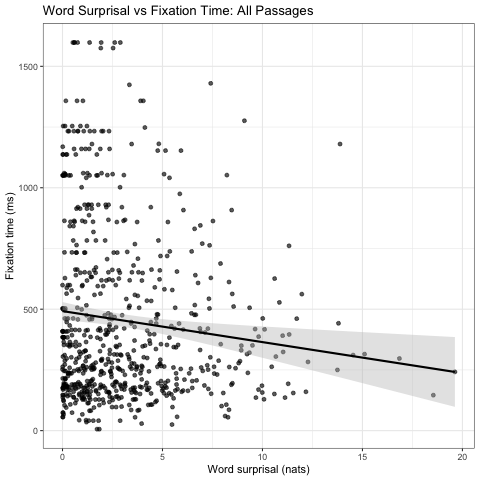

In [ ]:
%%R
library(ggplot2)

### START YOUR CODE ###
# Load ggplot2 and results/analysis_data.csv.
# Use all rows together to create one scatter plot and add a linear fitted
# curve with a 95% confidence interval using geom_smooth().
# Display the plot and save it as results/surprisal_vs_fixation_time.png.
### END YOUR CODE ###


---

## Submission requirement

Submit the completed notebook, and a zip file `results.zip` containing everything in the `results/` folder, which should include:
- `token_surprisals.json` produced from T2. 
- `word_surprisals.csv` and `analysis_data.csv` produced from T3.
- `correlation_summary.csv` and `surprisal_vs_fixation_time.png` from T4.